# Mechanics 3: Rotation

*Learning path: mechanics, part 3 of 7.* [Index](README.md) · Previous: [Energy and momentum](02-energy-and-momentum.ipynb) · Next: [Gravity and orbits](04-gravity-and-orbits.ipynb)

Set a top spinning and tilt it. Gravity pulls it down, so you expect it to fall over. Instead it swings slowly around
in a circle, its axis tracing a cone, and only falls once it has slowed down. A bicycle wheel held by one end of its
axle does the same thing, hanging sideways in the air. This lesson builds the rotational version of Newton's laws
(torque, moment of inertia, angular momentum) and uses it to explain the top.

**Who this is for.** You have done [lesson 2](02-energy-and-momentum.ipynb) and know the cross product of two vectors.

**What you will be able to do afterwards:**

1. compute a torque as a cross product $\tau = r \times F$;
2. compute moments of inertia by integration, and predict which shape rolls down a slope fastest;
3. use conservation of angular momentum;
4. explain and compute the precession of a spinning top.

Plan about an hour and a half.

## 1. Torque

To turn a nut you push on the end of a wrench, not near the nut. What matters is the **torque**
$\tau = r \times F$, where $r$ runs from the axis to the point where the force acts. Its size is $|r|\,|F|\sin\theta$
(force times lever arm), and its direction is the axis the force tries to turn about, by the right-hand rule. A 20 N
push straight down at the end of a 30 cm wrench lying along $x$:

In [1]:
cross([0.3, 0, 0] m, [0, 0, -20] N)

[0, 6.0, 0] N*m

> `cross` (see `dot`): Dot product of two vectors, and cross product of two vectors of length 3.

6 N·m about the $y$ axis. Push at half the distance and the torque halves; push along the wrench and it is zero.

For a body turning about a fixed axis, Newton's second law becomes $\tau = I\alpha$: torque equals the **moment of
inertia** $I$ times the angular acceleration $\alpha = d\omega/dt$. The moment of inertia plays the role of mass: it
measures how hard the body is to spin up.

**Try this.** A door is 90 cm wide. How hard must you push at the handle (at the edge) to give the same torque as a
50 N push 10 cm from the hinge?

## 2. Moments of inertia

Each small piece of mass $dm$ at distance $r$ from the axis moves at speed $\omega r$, so the kinetic energy is
$\tfrac12\int r^2\omega^2\,dm = \tfrac12 I\omega^2$ with $I = \int r^2\,dm$. For a thin rod of mass $M$ and length
$L$, $dm = (M/L)\,dx$. Turned about one end, and about its middle:

In [2]:
integrate(x^2*M/L, x, 0, L)
integrate(x^2*M/L, x, -L/2, L/2)

L^2*M/3

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

L^2*M/12

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

The same rod is four times easier to spin about its middle: mass far from the axis counts with the square of the
distance. A flat disk of radius $R$ is a stack of rings, each of mass $dm = (M/\pi R^2)\,2\pi r\,dr$:

In [3]:
integrate(r^2*M/(pi*R^2)*2*pi*r, r, 0, R)

M*R^2/2

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

A solid ball is a stack of thin spherical shells. A shell of radius $r$ has $I = \tfrac23 r^2\,dm$ (exercise 3), and
$dm = (3M/4\pi R^3)\,4\pi r^2\,dr$:

In [4]:
integrate(2/3*r^2*3*M/(4*pi*R^3)*4*pi*r^2, r, 0, R)

2*M*R^2/5

> `integrate`: Antiderivative of f with respect to x (without the constant; log(x) stands for log|x|), or the definite integral from a to b.

All these are $I = cMR^2$ with a number $c$: 1 for a hoop (all mass at the rim), $\tfrac12$ for a disk, $\tfrac25$ for
a ball.

**The race down the slope.** Let a hoop, a disk and a ball roll without slipping down a slope at angle $\theta$. Rolling
means $v = \omega R$, so the kinetic energy is $\tfrac12Mv^2 + \tfrac12 cMR^2(v/R)^2 = \tfrac12(1+c)Mv^2$. Part of the
energy goes into spinning, and the rest of the argument (exercise 4) gives the acceleration $a = g\sin\theta/(1+c)$.
For a disk:

In [5]:
a(c) := g*sin(th)/(1 + c);
a(1/2)

2*g*sin(th)/3

The mass and the radius have dropped out: any disk beats any hoop. Times to roll 2 m down a 30° slope, for the hoop,
the disk, the ball and (for comparison) a block sliding without friction, $c = 0$:

In [6]:
T(c) := sqrt(2*(2 m)/(const.g*sin(30 deg)/(1 + c)));
eval(T(1), 3)
eval(T(1/2), 3)
eval(T(2/5), 3)
eval(T(0), 3)

1.28 s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.11 s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

1.07 s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

0.903 s

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

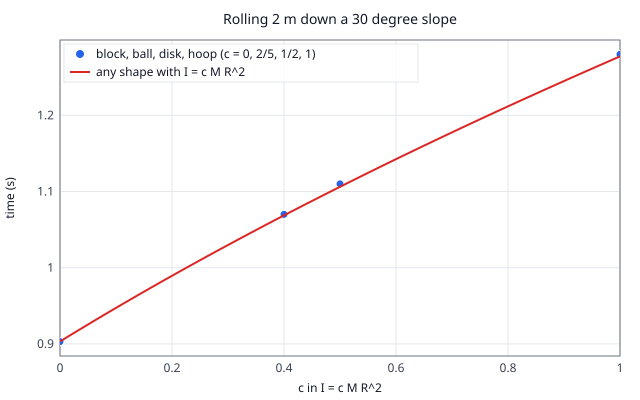

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [7]:
p = scatter([0, 2/5, 1/2, 1], [0.903, 1.07, 1.11, 1.28]);
p = show(p, plot(sqrt(2*2/(9.80665*0.5/(1 + c))), c, 0, 1));
p = legend(p, "block, ball, disk, hoop (c = 0, 2/5, 1/2, 1)", "any shape with I = c M R^2");
labels(title(p, "Rolling 2 m down a 30 degree slope"), "c in I = c M R^2", "time (s)")

The ball wins, then the disk, then the hoop. A full can of soup (whose liquid barely turns) beats an empty can (a hoop).

**Try this.** A thin spherical shell (a ping-pong ball) has $c = \tfrac23$. Where does it finish?

## 3. Angular momentum

The rotational partner of momentum is **angular momentum**. For a point mass it is $L = r \times p$; for a body
turning about a symmetry axis it is $L = I\omega$. Newton's second law for rotation reads $dL/dt = \tau$, so with no
outside torque $L$ is conserved, just as momentum is conserved with no outside force.

A figure skater spins at one turn per 1.5 s with arms out, $I_1 = 3.5$ kg·m². Pulling the arms in brings $I$ down to
$I_2 = 1.0$ kg·m². No outside torque acts (the ice is nearly frictionless), so $I_1\omega_1 = I_2\omega_2$:

In [8]:
I1 = 3.5 kg*m^2;
I2 = 1.0 kg*m^2;
w1 = 2*pi/(1.5 s);
eval(w1*I1/I2, 3)
eval(I1/I2/(1.5 s), 3)

14.7 s^-1

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

2.33 s^-1

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

14.7 radians per second, or 2.33 turns per second: more than three times as fast. (Galileo prints radians per second
as $\mathrm{s}^{-1}$, because an angle in radians is a plain number.) The energy is not conserved: it grows from
$\tfrac12I_1\omega_1^2$ to $\tfrac12I_2\omega_2^2 = (I_1/I_2)\,\tfrac12 I_1\omega_1^2$. The extra comes from the work
her arms do pulling inwards.

In [9]:
simplify((L^2/(2*I2))/(L^2/(2*I1)))

3.5

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

**Try this.** A diver tucks from $I = 12$ to $I = 4$ kg·m² in the air. How does the rate of turning change?

## 4. The spinning top

Now the top. It spins fast about its own axis, so its angular momentum $L$ points along the axis, with size $I\omega$.
Its centre of mass sits a distance $d$ up the axis from the point on the table, so gravity gives a torque
$\tau = d\hat L \times (-mg\hat z)$ about that point, where $\hat L = L/|L|$.

That torque is **horizontal and perpendicular to $L$**. By $dL/dt = \tau$, it does not make $L$ longer or shorter, and
it does not tip it down: it pushes the tip of $L$ sideways. The axis keeps turning sideways, in a horizontal circle.
That is **precession**. Write $\Omega = mgd/|L|$, and the equation is $dL/dt = \Omega\,L \times (-\hat z)$.

A toy top: $m = 0.1$ kg, $d = 4$ cm, $I = 4\cdot10^{-5}$ kg·m², spinning at 200 radians per second (about 32 turns per
second) and tilted 30° from upright.

In [10]:
mgd = 0.1*9.81*0.04;
L0 = 4e-5*200;
Om = mgd/L0
tau = Om*cross([Lx, Ly, Lz], [0, 0, -1])

4.905

[-4.905*Ly, 4.905*Lx, 0]

Solve $dL/dt = \tau$ numerically for 2.56 s and look at $L$ from above:

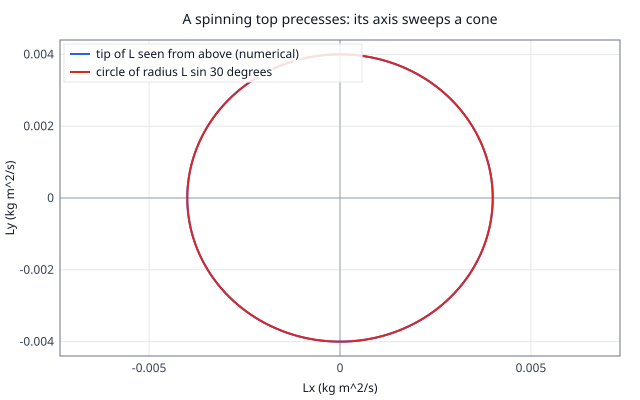

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [11]:
start = [L0*sin(pi/6), 0, L0*cos(pi/6)];
p = odeplot(tau, [Lx Ly Lz], t, start, 0, 2.56, [Lx Ly]);
p = show(p, parametric(L0/2*cos(Om*t), L0/2*sin(Om*t), t, 0, 2*pi/Om));
p = legend(p, "tip of L seen from above (numerical)", "circle of radius L sin 30 degrees");
labels(title(p, "A spinning top precesses: its axis sweeps a cone"), "Lx (kg m^2/s)", "Ly (kg m^2/s)")

A circle: the axis sweeps around a cone at a steady tilt. The vertical part of $L$ never changes:

In [12]:
D = odedata(tau, [Lx Ly Lz], t, start, 0, 2.56, 256);
eval([D(1, 4), D(129, 4), D(257, 4)], 4)

[0.006928, 0.006928, 0.006928]

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

The precession rate is $\Omega = mgd/(I\omega)$, so one circuit takes

In [13]:
eval(2*pi/Om, 3)

1.28

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

about 1.28 s, while the top spins 32 times a second. The formula says something surprising: a top that spins
**faster** precesses **slower**. And as friction slows the spin, the precession speeds up, until the fast-top picture
breaks down and the top wobbles and falls. Here is the tip of the axis (at the centre of mass, 4 cm up) going around:

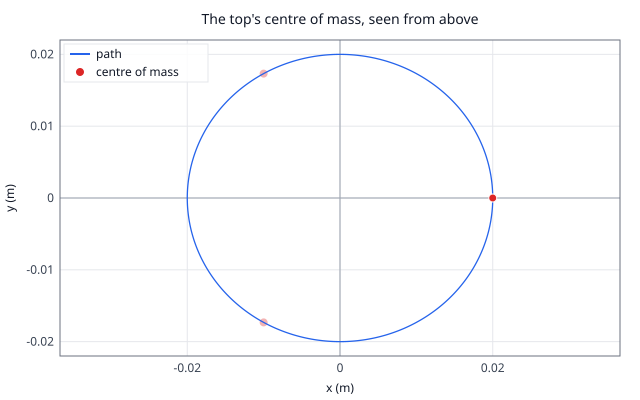

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [14]:
s = 0.04*sin(pi/6);
p = animate(s*cos(Om*t), s*sin(Om*t), t, 0, 2*pi/Om, 40);
p = legend(p, "path", "centre of mass");
labels(title(p, "The top's centre of mass, seen from above"), "x (m)", "y (m)")

The same physics steers a bicycle (lean, and the spinning front wheel turns into the lean), keeps a thrown frisbee
level, and makes the Earth's axis precess once every 26 000 years under the pull of the Sun and the Moon on its
equatorial bulge. Lesson 6 derives the full motion of the top, wobbles included.

**Try this.** Double the spin rate of the toy top. What is the new precession period?

## Summary

* Torque $\tau = r\times F$ is the turning effect of a force; $\tau = I\alpha$ for a fixed axis.
* The moment of inertia $I = \int r^2\,dm$ is the rotational mass: $\tfrac13ML^2$ for a rod about its end,
  $\tfrac12MR^2$ for a disk, $\tfrac25MR^2$ for a ball.
* Rolling shapes race by $c = I/MR^2$ alone: ball, then disk, then hoop.
* Angular momentum obeys $dL/dt = \tau$ and is conserved with no outside torque: skaters spin up.
* A torque perpendicular to $L$ turns it without changing its size: a top precesses at $\Omega = mgd/(I\omega)$.

Next: [gravity and orbits](04-gravity-and-orbits.ipynb), where angular momentum conservation becomes Kepler's second law.

## Exercises

1. **Seesaw.** A 30 kg child sits 2 m from the pivot. Where must a 45 kg child sit to balance?
2. **Flywheel.** A 20 kg disk flywheel of radius 0.3 m spins at 3000 turns per minute. How much energy does it store?
3. **Thin shell.** Show that a thin spherical shell has $I = \tfrac23MR^2$. Hint: put the axis along $z$; a point on
   the shell at angle $\theta$ from the axis is at distance $R\sin\theta$, and the band between $\theta$ and
   $\theta + d\theta$ has mass $\tfrac12 M\sin\theta\,d\theta$.
4. **Rolling acceleration.** Derive $a = g\sin\theta/(1+c)$ from energy: after rolling a distance $s$, the height lost
   is $s\sin\theta$. Compare $\tfrac12(1+c)Mv^2 = Mgs\sin\theta$ with $v^2 = 2as$.
5. **The Earth's spin.** Treat the Earth as a uniform ball (`const.Mearth`, `const.Rearth`). What is its angular
   momentum? (The real value is about 20% less, because the core is denser.)
6. **Collapsing star.** A star like the Sun ($R = 7\cdot10^5$ km) turning once a month collapses to a neutron star of
   radius 10 km. Assuming it stays a uniform ball, how fast does it turn?

## Hints and answers

* **Section 1, Try this.** $50 \cdot 0.1/0.9 \approx 5.6$ N.
* **Section 2, Try this.** $T(2/3) \approx 1.17$ s: after the disk, ahead of the hoop.
* **Section 3, Try this.** Three times faster.
* **Section 4, Try this.** Twice as long: about 2.56 s.
* **Exercise 1.** $30 \cdot 2 = 45x$, so $x = 1.33$ m.
* **Exercise 2.** $I = \tfrac12 \cdot 20 \cdot 0.3^2 = 0.9$ kg·m², $\omega = 100\pi$ per second, energy
  $\tfrac12I\omega^2 \approx 44$ kJ.
* **Exercise 3.** `integrate((R*sin(t))^2*M/2*sin(t), t, 0, pi)` gives $\tfrac23MR^2$.
* **Exercise 4.** $v^2 = 2gs\sin\theta/(1+c)$, and $v^2 = 2as$ gives $a$.
* **Exercise 5.** `eval(2/5*const.Mearth*const.Rearth^2*2*pi/(86164 s), 3)` gives about $7.1\cdot10^{33}$ kg·m²/s.
* **Exercise 6.** $\omega$ grows by $(R_1/R_2)^2 = 4.9\cdot10^9$: from one turn a month to about 1900 turns a second.
  Real pulsars spin up to about 700 times a second.

## Sources

1. L. Euler, *Theoria motus corporum solidorum seu rigidorum* (1765): rigid-body rotation and moments of inertia.
2. D. Kleppner and R. Kolenkow, *An Introduction to Mechanics*, 2nd ed., Cambridge University Press (2014), chapters 7
   and 8 (the gyroscope).
3. H. Goldstein, C. Poole and J. Safko, *Classical Mechanics*, 3rd ed., Addison-Wesley (2002), section 5.7 (the heavy
   symmetric top).